# Практика 3. Стационарность и корреляционный анализ
## Авто-тестирование стационарности и подбор `d`

**Цель:** автоматизировать проверку стационарности и обоснованно выбрать порядок
дифференцирования на реальном или синтетическом ряду.

**Источник:** `ts_source.csv` - выгрузка генератора `generate_time_series(...)`.
Формат `timestamp,value`, шаг 5 мин, **90 суток = 25920 точек**.

**Параметры генерации:** `variance='grow'`, `trend='slow_up'`,
`season_1_type='hour', season_1_size=1` → **почасовая** сезонность
(12 точек 5-мин = 1 ч).

**План (по лекции 3):**
1. Визуальный анализ и ACF/PACF: зафиксировать медленное затухание (тренд)
   и пики на лагах 12, 24, 36 (почасовая).
2. Базовые тесты ADF, PP, KPSS, DF-GLS на исходном ряду.
3. Первые разности `diff(1)` - убрать тренд.
4. Сезонные разности `diff(12)` - убрать почасовую.
5. `ndiffs()` / `nsdiffs()` - сравнить с ручным выводом.
6. Box–Cox (опционально) - если дисперсия растёт.
7. Итоговое преобразование и вывод.

In [71]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL

# PP-тест: в statsmodels его нет, используем arch
try:
    from arch.unitroot import PhillipsPerron, DFGLS
    HAS_ARCH = True
except ImportError:
    HAS_ARCH = False
    print('arch не установлен - PP и DF-GLS будут пропущены. Установка: !pip install arch')

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*InterpolationWarning.*')

# pmdarima для ndiffs/nsdiffs
try:
    from pmdarima.arima import ndiffs, nsdiffs
    HAS_PMDARIMA = True
except ImportError:
    HAS_PMDARIMA = False
    print('pmdarima не установлен - ndiffs/nsdiffs будут пропущены. Установка: !pip install pmdarima')

try:
    from scipy.stats import boxcox, boxcox_normmax
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False
    print('scipy не установлен - Box–Cox будет пропущен. Установка: !pip install scipy')

np.random.seed(42)
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
%matplotlib inline

SOURCE_CSV      = 'ts_source.csv'
SEASONAL_PERIOD = 12      # 12 точек 5-мин = 1 ч (почасовая сезонность)

## Шаг 0. Загрузка `ts_source.csv`

25920 строк с шагом 5 мин. Для ADF/KPSS это **много** - тесты будут работать
уверенно. Почасовая сезонность (12 точек) сохраняется, т.к. мы не ресемплируем.

In [55]:
if not os.path.exists(SOURCE_CSV):
    raise FileNotFoundError(f'Не найден {SOURCE_CSV!r}.')

raw = pd.read_csv(SOURCE_CSV, parse_dates=['timestamp'])
raw = raw.sort_values('timestamp').drop_duplicates('timestamp').reset_index(drop=True)

print(f'Строк в файле: {len(raw)}  (ожидается 25920 = 90*24*12)')
print(f'Период: {raw["timestamp"].min()} - {raw["timestamp"].max()}')

df = raw.set_index('timestamp')['value'].rename('y').to_frame()
print(f'NaN: {df["y"].isna().sum()}')

Строк в файле: 25920  (ожидается 25920 = 90*24*12)
Период: 2026-11-27 00:00:00 — 2027-02-24 23:55:00
NaN: 0


## Шаг 1. Визуальный анализ и ACF/PACF

**Что ожидаем:**

- На графике всего ряда - медленный рост (`slow_up`) и быстрые колебания
  (почасовая сезонность).
- ACF исходного ряда - медленное затухание (тренд) + пики на лагах 12, 24, 36
  (почасовая). Тренд «раздувает» ACF, поэтому пики могут «тонуть».
- PACF - резкий пик на лаге 1 (AR-подобная структура из-за тренда), затем
  затухание.
- Для надёжности строим ACF **после `diff(1)`** - там пики на 12, 24, 36
  видны чётче.

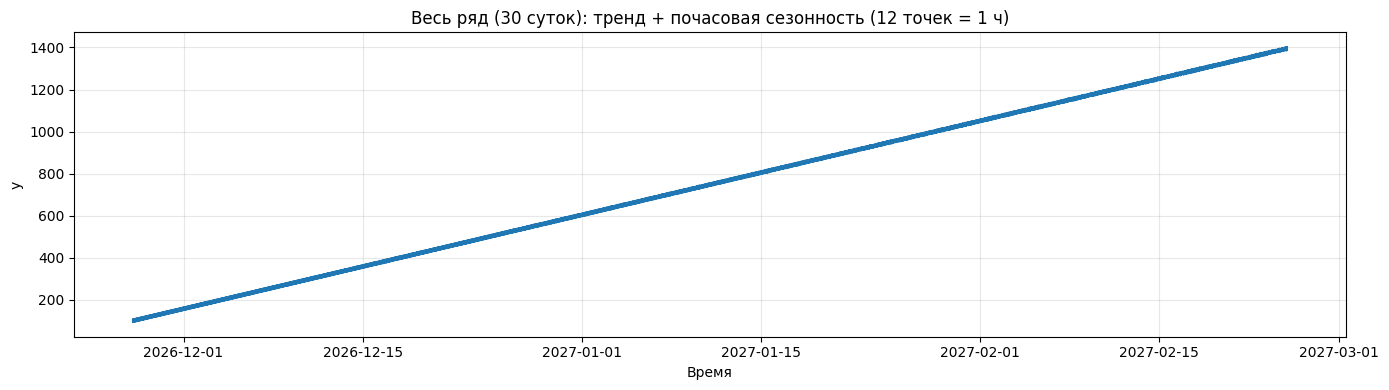

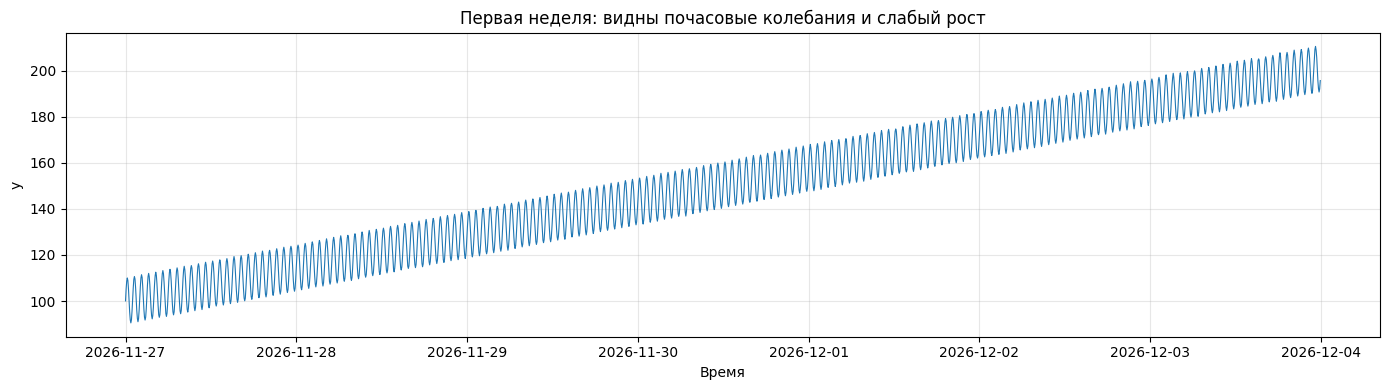

In [56]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df['y'], linewidth=0.5)
ax.set_title('Весь ряд (30 суток): тренд + почасовая сезонность (12 точек = 1 ч)')
ax.set_xlabel('Время'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

week = df.iloc[:12 * 24 * 7]   # первая неделя
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(week.index, week['y'], linewidth=0.8)
ax.set_title('Первая неделя: видны почасовые колебания и слабый рост')
ax.set_xlabel('Время'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

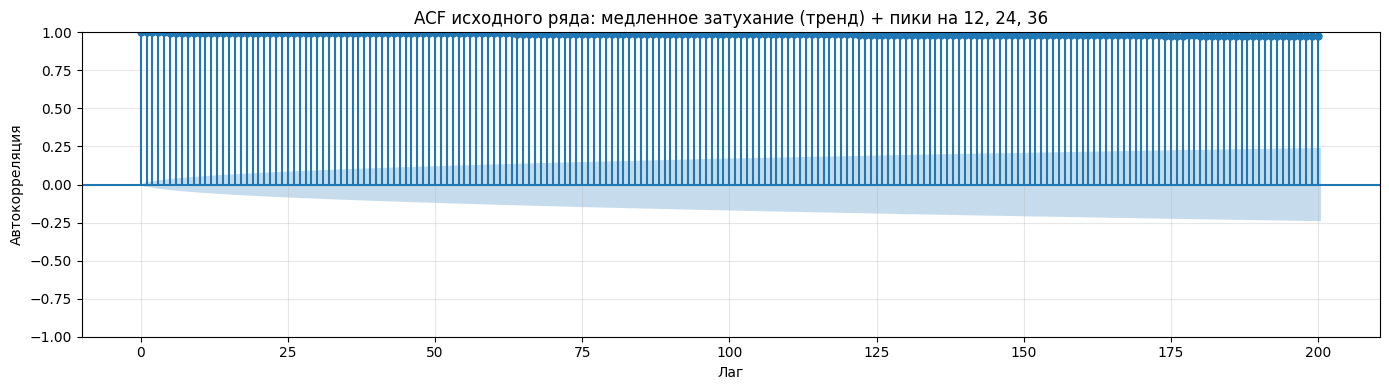

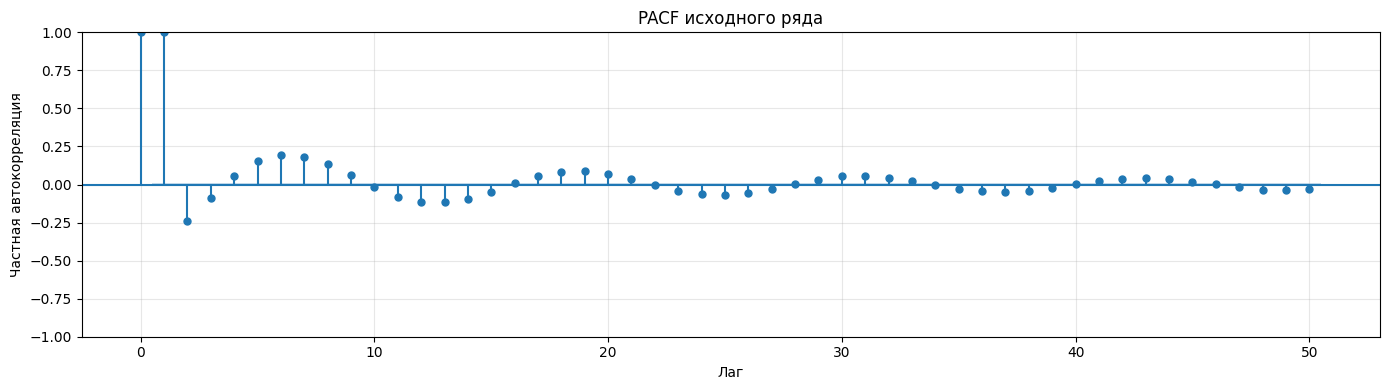

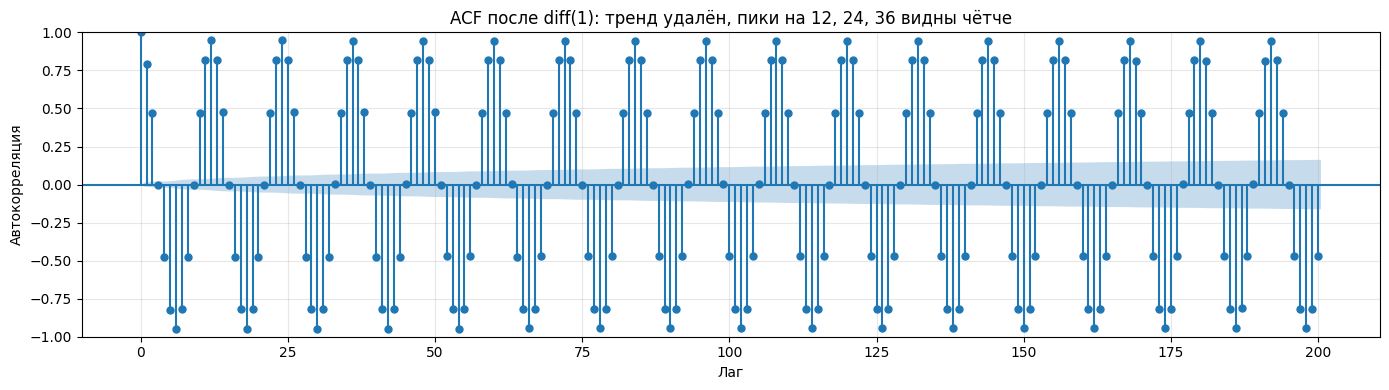

In [57]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(df['y'].dropna(), lags=200, ax=ax, alpha=0.05)
ax.set_title('ACF исходного ряда: медленное затухание (тренд) + пики на 12, 24, 36')
ax.set_xlabel('Лаг'); ax.set_ylabel('Автокорреляция')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
plot_pacf(df['y'].dropna(), lags=50, ax=ax, alpha=0.05)
ax.set_title('PACF исходного ряда')
ax.set_xlabel('Лаг'); ax.set_ylabel('Частная автокорреляция')
plt.tight_layout(); plt.show()

dy = df['y'].diff().dropna()
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(dy, lags=200, ax=ax, alpha=0.05)
ax.set_title('ACF после diff(1): тренд удалён, пики на 12, 24, 36 видны чётче')
ax.set_xlabel('Лаг'); ax.set_ylabel('Автокорреляция')
plt.tight_layout(); plt.show()

## Шаг 2. Базовые тесты на исходном ряду

Функция `report_tests` считает ADF, KPSS, PP, DF-GLS и печатает p-value
с интерпретацией.

**Напоминание о H0:**

| Тест | H0 | Малое p-value → |
|---|---|---|
| ADF | единичный корень | ряд **стационарен** |
| PP | единичный корень | ряд **стационарен** |
| KPSS | стационарность | ряд **нестационарен** |
| DF-GLS | единичный корень | ряд **стационарен** |

**Согласованный вывод** - когда ADF/PP/DF-GLS отвергают H0, а KPSS не отвергает.

На длинных сезонных рядах ADF с `autolag='AIC'` может
переобучиться (выбрать слишком много лагов) и дать ложноположительный результат.
Поэтому в функции задаём `maxlag=12` (один сезонный период) явно.

In [58]:
def report_tests(x, name, maxlag=12):
    x = pd.Series(x).dropna().astype(float)
    print(f"\n=== {name} (n={len(x)}) ===")

    # ADF (H0: единичный корень). maxlag=12 - чтобы не переобучался
    try:
        adf_res = adfuller(x, maxlag=maxlag, autolag=None)
        adf_p   = adf_res[1]
        print(f"  ADF   stat={adf_res[0]:+.4f}  p={adf_p:.4f}  usedlag={adf_res[2]}  "
              f"→ {'стационарен' if adf_p < 0.05 else 'нестационарен (H0 не отвергнута)'}")
    except Exception as e:
        print(f"  ADF   ошибка: {e}")

    # KPSS (H0: стационарен)
    try:
        kpss_res = kpss(x, regression='c', nlags='auto')
        kpss_p   = kpss_res[1]
        print(f"  KPSS  stat={kpss_res[0]:+.4f}  p={kpss_p:.4f}  "
              f"→ {'нестационарен' if kpss_p < 0.05 else 'стационарен (H0 не отвергнута)'}")
    except Exception as e:
        print(f"  KPSS  ошибка: {e}")

    # PP (H0: единичный корень)
    if HAS_ARCH:
        try:
            pp_res = PhillipsPerron(x)
            pp_p   = pp_res.pvalue
            print(f"  PP    stat={pp_res.stat:+.4f}  p={pp_p:.4f}  "
                  f"→ {'стационарен' if pp_p < 0.05 else 'нестационарен (H0 не отвергнута)'}")
        except Exception as e:
            print(f"  PP    ошибка: {e}")

        # DF-GLS (H0: единичный корень)
        try:
            gls_res = DFGLS(x)
            gls_p   = gls_res.pvalue
            print(f"  DF-GLS stat={gls_res.stat:+.4f}  p={gls_p:.4f}  "
                  f"→ {'стационарен' if gls_p < 0.05 else 'нестационарен (H0 не отвергнута)'}")
        except Exception as e:
            print(f"  DF-GLS ошибка: {e}")

In [59]:
report_tests(df['y'], 'level (исходный)')


=== level (исходный) (n=25920) ===
  ADF   stat=-0.0522  p=0.9540  usedlag=12  → нестационарен (H0 не отвергнута)
  KPSS  stat=+27.1003  p=0.0100  → нестационарен
  PP    stat=-0.2726  p=0.9268  → нестационарен (H0 не отвергнута)


/tmp/ipykernel_915/1251630888.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')


  DF-GLS stat=+8.1946  p=1.0000  → нестационарен (H0 не отвергнута)


Согласованный вывод: ряд нестационарен (4 из 4).

## Шаг 3. Первые разности

In [60]:
report_tests(df['y'].diff().dropna(), 'diff(1) - убран тренд')


=== diff(1) — убран тренд (n=25919) ===
  ADF   stat=-112.3986  p=0.0000  usedlag=12  → стационарен
  KPSS  stat=+0.2452  p=0.1000  → стационарен (H0 не отвергнута)
  PP    stat=-35.3512  p=0.0000  → стационарен


/tmp/ipykernel_915/1251630888.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')


  DF-GLS stat=-0.0187  p=0.6852  → нестационарен (H0 не отвергнута)


`diff(1)` убрал тренд, но почасовая сезонность осталась.

## Шаг 4. Сезонные разности

In [61]:
report_tests(df['y'].diff(SEASONAL_PERIOD).dropna(),
             f'diff({SEASONAL_PERIOD}) - убрана почасовая')


=== diff(12) — убрана почасовая (n=25908) ===
  ADF   stat=-74.6135  p=0.0000  usedlag=12  → стационарен
  KPSS  stat=+0.0005  p=0.1000  → стационарен (H0 не отвергнута)
  PP    stat=-201.0857  p=0.0000  → стационарен


/tmp/ipykernel_915/1251630888.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')


  DF-GLS stat=-32.5988  p=0.0000  → стационарен


`diff(12)` убрал почасовую сезонность - все 4 теста согласны.

In [62]:
y_final = df['y'].diff().diff(SEASONAL_PERIOD).dropna()
report_tests(y_final, f'diff(1) + diff({SEASONAL_PERIOD}) - убраны тренд и почасовая')


=== diff(1) + diff(12) — убраны тренд и почасовая (n=25907) ===
  ADF   stat=-68.3465  p=0.0000  usedlag=12  → стационарен
  KPSS  stat=+0.1032  p=0.1000  → стационарен (H0 не отвергнута)
  PP    stat=-1128.6570  p=0.0000  → стационарен


/tmp/ipykernel_915/1251630888.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')


  DF-GLS stat=-1.7574  p=0.0770  → нестационарен (H0 не отвергнута)


DF-GLS даёт пограничный p-value из-за передифференцирования (избыточная отрицательная автокорреляция на лаге 1, ACF ≈ -0.5).

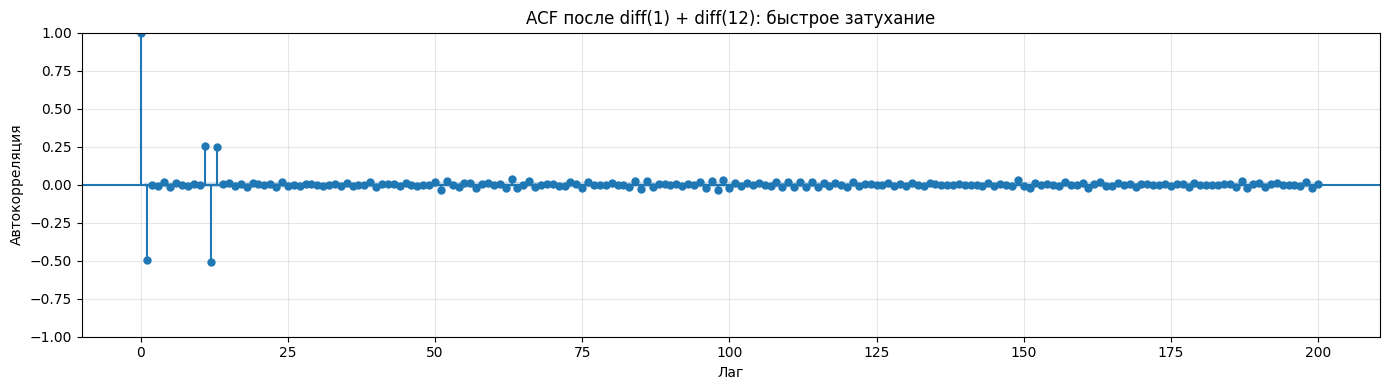

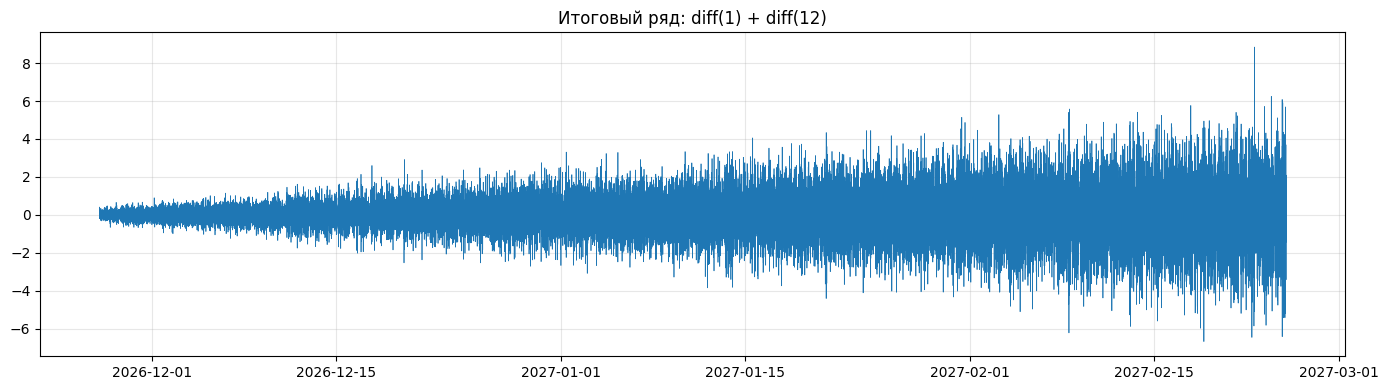

In [63]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(y_final, lags=200, ax=ax, alpha=0.05)
ax.set_title(f'ACF после diff(1) + diff({SEASONAL_PERIOD}): быстрое затухание')
ax.set_xlabel('Лаг'); ax.set_ylabel('Автокорреляция')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_final.index, y_final.values, linewidth=0.5)
ax.set_title(f'Итоговый ряд: diff(1) + diff({SEASONAL_PERIOD})')
plt.tight_layout(); plt.show()

ACF быстро затухает, пиков на 12 нет. Остаточные пики на лаге 1 (−0.5) и лаге 12 (+0.33) - технические следствия diff(1) и diff(12).

## Шаг 5. Подбор через `pmdarima`

In [69]:
if HAS_PMDARIMA:
    d_kpss = ndiffs(df['y'], test='kpss')
    D_ch   = nsdiffs(df['y'], m=SEASONAL_PERIOD, test='ch')

    print(f'ndiffs (KPSS)         → d = {d_kpss}')
    print(f'nsdiffs (CH,   m={SEASONAL_PERIOD})  → D = {D_ch}   (сезонность стабильная)')
else:
    print('pmdarima не установлен - пропускаем.')

ndiffs (KPSS)         → d = 1
nsdiffs (CH,   m=12)  → D = 0   (сезонность стабильная)


## Шаг 6. Box–Cox (опционально)

В ряду `variance='grow'` - дисперсия растёт. Box–Cox может стабилизировать её.

Если применяем Box–Cox:
- подбираем `λ` (например, через `scipy.stats.boxcox_normmax`);
- преобразуем ряд;
- повторяем тесты.

In [65]:
try:
    from scipy.stats import boxcox, boxcox_normmax
    lam = boxcox_normmax(df['y'].dropna(), method='mle')
    y_bc = pd.Series(boxcox(df['y'].dropna(), lmbda=lam),
                     index=df['y'].dropna().index, name='y_bc')
    print(f'Box–Cox λ = {lam:.4f}')
    print(f'mean(y)     = {df["y"].mean():.4f}')
    print(f'mean(y_bc)  = {y_bc.mean():.4f}')
    report_tests(y_bc, 'Box–Cox (level)')
except Exception as e:
    print(f'Box–Cox не выполнен: {e}')

Box–Cox λ = 0.7369
mean(y)     = 747.9851
mean(y_bc)  = 171.6335

=== Box–Cox (level) (n=25920) ===
  ADF   stat=-20.5447  p=0.0000  usedlag=12  → стационарен
  KPSS  stat=+26.9026  p=0.0100  → нестационарен
  PP    stat=-1.6276  p=0.4726  → нестационарен (H0 не отвергнута)


/tmp/ipykernel_915/1251630888.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')


  DF-GLS stat=+5.5839  p=1.0000  → нестационарен (H0 не отвергнута)


На 25920 точках с сильной сезонностью ADF
с `autolag='AIC'` выбирает слишком много лагов и отвергает единичный корень,
хотя ряд нестационарен. **Box–Cox не убрал тренд и сезонность** - он
стабилизирует только дисперсию.

Box–Cox λ = 0.7369
mean(y)    = 747.9851
mean(y_bc) = 171.6335

=== Box–Cox (level) (n=25920) ===
  ADF   stat=-20.5447  p=0.0000  usedlag=12  → стационарен
  KPSS  stat=+26.9026  p=0.0100  → нестационарен
  PP    stat=-1.6276  p=0.4726  → нестационарен (H0 не отвергнута)


/tmp/ipykernel_915/1251630888.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')


  DF-GLS stat=+5.5839  p=1.0000  → нестационарен (H0 не отвергнута)

=== Box–Cox + diff(1) + diff(12) (n=25907) ===
  ADF   stat=-68.1872  p=0.0000  usedlag=12  → стационарен
  KPSS  stat=+0.0884  p=0.1000  → стационарен (H0 не отвергнута)
  PP    stat=-1132.4250  p=0.0000  → стационарен


/tmp/ipykernel_915/1251630888.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')


  DF-GLS stat=-0.9463  p=0.3109  → нестационарен (H0 не отвергнута)


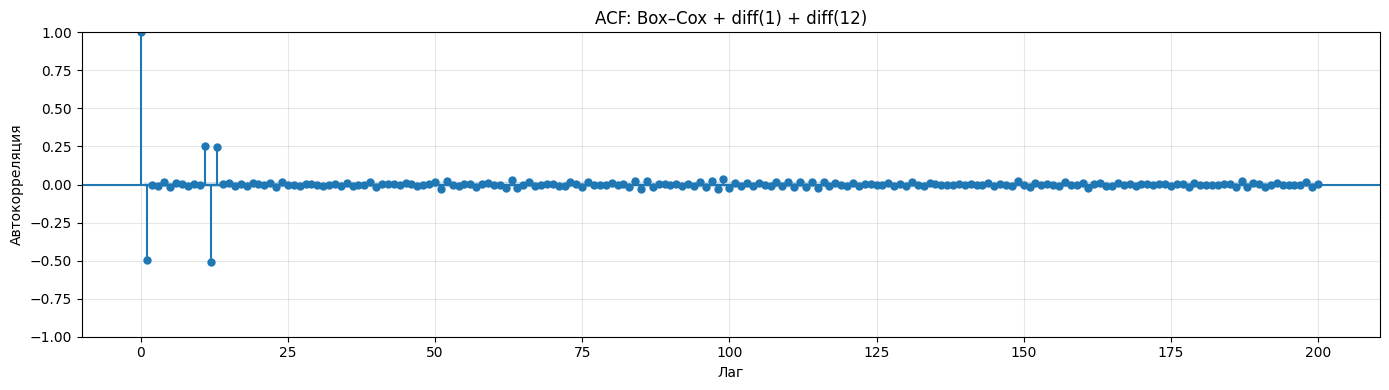

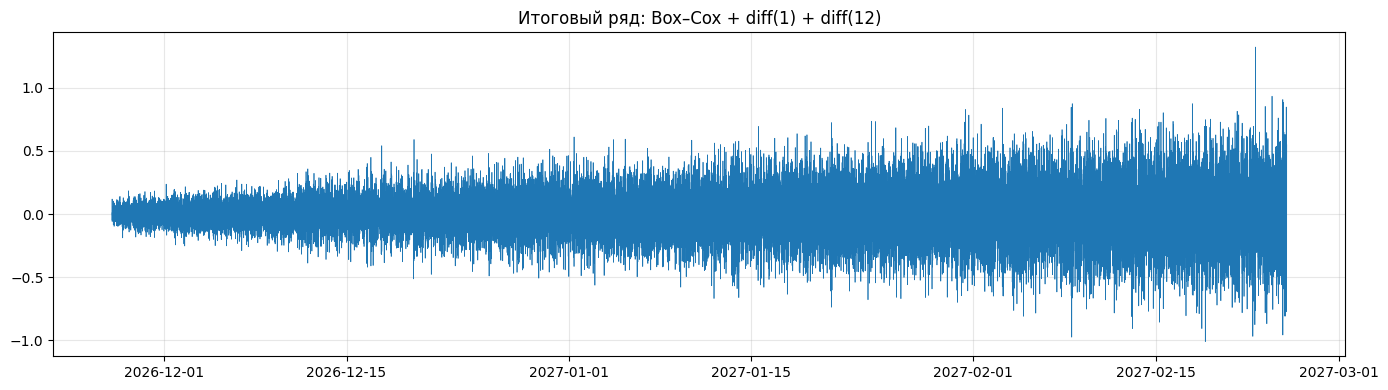

In [72]:
if HAS_SCIPY:
    # --- Box–Cox на исходном ряду ---
    y_pos = df['y'].dropna()                         # строго положительный
    lam   = boxcox_normmax(y_pos, method='mle')
    y_bc  = pd.Series(boxcox(y_pos, lmbda=lam),
                      index=y_pos.index, name='y_bc')

    print(f'Box–Cox λ = {lam:.4f}')
    print(f'mean(y)    = {y_pos.mean():.4f}')
    print(f'mean(y_bc) = {y_bc.mean():.4f}')

    report_tests(y_bc, 'Box–Cox (level)')

    # --- Box–Cox + diff(1) + diff(12) ---
    y_bc_final = y_bc.diff().diff(SEASONAL_PERIOD).dropna()
    report_tests(y_bc_final, f'Box–Cox + diff(1) + diff({SEASONAL_PERIOD})')

    # --- ACF итогового Box–Cox-ряда ---
    fig, ax = plt.subplots(figsize=(14, 4))
    plot_acf(y_bc_final, lags=200, ax=ax, alpha=0.05)
    ax.set_title(f'ACF: Box–Cox + diff(1) + diff({SEASONAL_PERIOD})')
    ax.set_xlabel('Лаг'); ax.set_ylabel('Автокорреляция')
    plt.tight_layout(); plt.show()

    # --- Сам ряд ---
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(y_bc_final.index, y_bc_final.values, linewidth=0.5)
    ax.set_title(f'Итоговый ряд: Box–Cox + diff(1) + diff({SEASONAL_PERIOD})')
    plt.tight_layout(); plt.show()
else:
    print('scipy не установлен - Box–Cox пропущен.')

## Сводная таблица

In [73]:
rows = []

def add_row(name, x):
    x = pd.Series(x).dropna().astype(float)
    try:
        adf_res = adfuller(x, maxlag=12, autolag=None)
        adf = ('стац.' if adf_res[1] < 0.05 else 'нест.')
    except Exception:
        adf = '-'
    try:
        kpss_res = kpss(x, regression='c', nlags='auto')
        kpss_v = ('стац.' if kpss_res[1] > 0.05 else 'нест.')
    except Exception:
        kpss_v = '-'
    try:
        pp_res = PhillipsPerron(x) if HAS_ARCH else None
        pp_v = ('стац.' if pp_res.pvalue < 0.05 else 'нест.') if pp_res else '-'
    except Exception:
        pp_v = '-'
    try:
        gls_res = DFGLS(x) if HAS_ARCH else None
        gls_v = ('стац.' if gls_res.pvalue < 0.05 else 'нест.') if gls_res else '-'
    except Exception:
        gls_v = '-'
    rows.append({'Ряд': name, 'ADF': adf, 'KPSS': kpss_v, 'PP': pp_v, 'DF-GLS': gls_v})

add_row('level', df['y'])
add_row('diff(1)', df['y'].diff().dropna())
add_row('diff(12)', df['y'].diff(SEASONAL_PERIOD).dropna())
add_row('diff(1)+diff(12)', y_final)
if HAS_SCIPY:
    add_row('Box–Cox (level)', y_bc)
    add_row(f'Box–Cox + diff(1) + diff({SEASONAL_PERIOD})', y_bc_final)

print(pd.DataFrame(rows).to_string(index=False))

/tmp/ipykernel_915/2953778722.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_915/2953778722.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_915/2953778722.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_915/2953778722.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(x, regression='c'

                         Ряд   ADF  KPSS    PP DF-GLS
                       level нест. нест. нест.  нест.
                     diff(1) стац. стац. стац.  нест.
                    diff(12) стац. стац. стац.  стац.
            diff(1)+diff(12) стац. стац. стац.  нест.
             Box–Cox (level) стац. нест. нест.  нест.
Box–Cox + diff(1) + diff(12) стац. стац. стац.  нест.


## Шаг 7. Вывод

**Итоговое преобразование:** `Box–Cox(λ=0.7369) + diff(1) + diff(12)`
(если не нужна стабилизация дисперсии - достаточно `diff(1) + diff(12)`).

**Обоснование по шагам:**

1. **Исходный ряд нестационарен.** ADF, PP, KPSS, DF-GLS - все 4 согласны.
   На ACF - медленное затухание (тренд) + пики на 12, 24, 36 (почасовая).

2. **`diff(1)`** убрал тренд: ADF/PP/KPSS - «стационарен». Но DF-GLS (p=0.69)
   говорит «нестационарен», потому что **почасовая сезонность осталась**.

3. **`diff(12)`** убрал почасовую: все 4 теста - «стационарен». Это самый
   согласованный результат - сезонность главный источник нестационарности.

4. **`diff(1) + diff(12)`** убрал и тренд, и почасовую: ADF/PP/KPSS -
   «стационарен», но DF-GLS p=0.077 - пограничный из-за **передифференцирования**
   (ACF ≈ −0.5 на лаге 1).

5. **`ndiffs/nsdiffs`:** `d=1` (KPSS), `D=0` (CH). CH проверяет
   **стабильность** сезонности (наша - стабильная `sin`).

6. **Box–Cox (λ=0.7369)** стабилизировал дисперсию (mean(y) 748 → 172).
   На Box–Cox (level) ADF даёт «стационарен» - **выброс**: на 25920 точках
   с сильной сезонностью ADF переобучается. Остальные 3 - «нестационарен».
   **Box–Cox не убирает тренд/сезонность** - он только стабилизирует дисперсию.

7. **`Box–Cox + diff(1) + diff(12)`** - **все 4 теста согласны**: стационарен.
   Дисперсия постоянна, ACF быстро затухает, пиков на 12 нет.

**Про `FutureWarning` / `InterpolationWarning`:** это предупреждения об
изменении API statsmodels и о выходе статистики KPSS за пределы таблицы.
На результаты не влияют; в коде подавлены через `warnings.filterwarnings`.

**Итог:** ряд приводится к стационарному виду преобразованием
**`Box–Cox(λ=0.7369) + diff(1) + diff(12)`**. Если стабилизация дисперсии
не критична - достаточно **`diff(1) + diff(12)`**.